In [1]:
import sys

print(sys.executable)
print(sys.version)

/home/alan/anaconda3/envs/mlops/bin/python
3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:21:38) [GCC 14.3.0]


In [2]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

In [3]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [4]:
print(Path.cwd())

list(Path("data").glob("*.parquet"))

/mnt/c/Users/alan_/Documents/learning-mlops


[PosixPath('data/yellow_tripdata_2021-01.parquet'),
 PosixPath('data/yellow_tripdata_2021-02.parquet'),
 PosixPath('data/yellow_tripdata_2026-05.parquet')]

In [5]:
df = pd.read_parquet(data_path)

df.shape

(4090836, 20)

In [6]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance"
]

df[columns].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2026-05-01 00:04:59,2026-05-01 00:32:48,138,37,7.51
1,2026-05-01 00:37:05,2026-05-01 00:59:47,138,237,6.14
2,2026-05-01 00:34:05,2026-05-01 00:54:02,249,232,2.40
3,2026-05-01 00:55:07,2026-05-01 01:02:43,232,114,1.20
4,2026-05-01 00:44:13,2026-05-01 00:44:13,140,237,0.86


In [7]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

In [8]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

(3883752, 22)

In [9]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

In [10]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)

(160000, 40000)

In [11]:
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape

((160000, 12641), (40000, 12641))

In [12]:
#Linear model

In [13]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)

linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse

6.6529873894522495

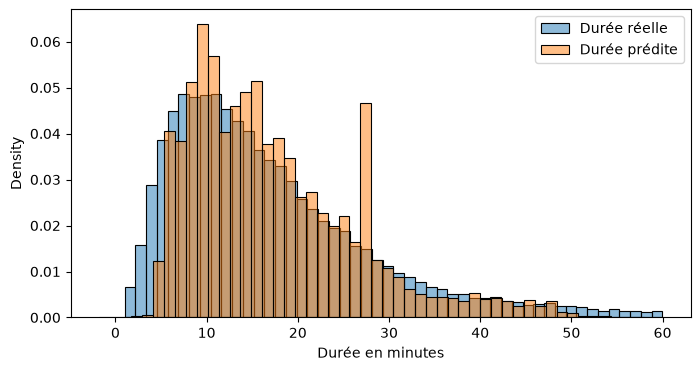

In [14]:
plt.figure(figsize=(8, 4))

sns.histplot(
    y_val,
    label="Durée réelle",
    stat="density",
    bins=50,
    alpha=0.5
)

sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5
)

plt.xlabel("Durée en minutes")
plt.legend()
plt.show()

In [15]:
#Lasso model

In [16]:
X_train.indices = X_train.indices.astype("int32")
X_train.indptr = X_train.indptr.astype("int32")

X_val.indices = X_val.indices.astype("int32")
X_val.indptr = X_val.indptr.astype("int32")

In [17]:
X_train.indices.dtype, X_val.indices.dtype

(dtype('int32'), dtype('int32'))

In [18]:
lasso_model = Lasso(alpha=0.01, max_iter=10_000)

lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)

lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

10.517043400486218

In [19]:
#XGBRegressor model

In [20]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)

xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse

6.471618951707119

In [21]:
results = pd.DataFrame({
    "model": ["LinearRegression", "Lasso", "XGBoost"],
    "rmse": [linear_rmse, lasso_rmse, xgb_rmse]
}).sort_values("rmse")

results

,model,rmse
2,XGBoost,6.471619
0,LinearRegression,6.652987
1,Lasso,10.517043


In [22]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse)
}

selected_name = min(models, key=lambda name: models[name][1])

selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

model_path = models_dir / "duration_model.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path

('XGBoost', 6.471618951707119, PosixPath('models/duration_model.bin'))

In [23]:
#notre modèle sauvegardé peut effectuer une prédiction sans être entraîné de nouveau
#Cette étape est fondamentale en MLOps : nous séparons l'entraînement du modèle de son utilisation pour effectuer des prédictions.
#C'est ce qu'on appelle l'inférence (inference).

In [24]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [
    {"PU_DO": "161_236", "trip_distance": 3.2}
]

example_matrix = loaded_dv.transform(example)

prediction = loaded_model.predict(example_matrix)[0]

prediction

np.float32(21.65231)

1. Étape 15/16 — Expérimentations supplémentaires
D'après les consignes précédemment partagées, il nous reste à réaliser plusieurs expérimentations :
- Tester deux autres valeurs de alpha pour Lasso.
- Modifier un hyperparamètre de XGBoost.
- Comparer les nouveaux RMSE.
- Sélectionner le meilleur modèle et justifier notre choix.
- Identifier les informations nécessaires à la reproductibilité

2. Première expérimentation — Lasso avec alpha = 0.001
Notre première configuration de Lasso utilisait alpha=0.01. Nous allons maintenant diminuer la force de régularisation.

In [25]:
lasso_model_2 = Lasso(alpha=0.001, max_iter=10_000)

lasso_model_2.fit(X_train, y_train)

lasso_predictions_2 = lasso_model_2.predict(X_val)

lasso_rmse_2 = root_mean_squared_error(y_val, lasso_predictions_2)

lasso_rmse_2

7.877294379084631

In [26]:
lasso_model_3 = Lasso(alpha=0.0001, max_iter=10_000)

lasso_model_3.fit(X_train, y_train)

lasso_predictions_3 = lasso_model_3.predict(X_val)

lasso_rmse_3 = root_mean_squared_error(y_val, lasso_predictions_3)

lasso_rmse_3

6.729967150195601

2. Troisième expérimentation — Modifier XGBoost
Le professeur demande de modifier un hyperparamètre de XGBoost.

In [27]:
xgb_model_2 = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model_2.fit(X_train, y_train)

xgb_predictions_2 = xgb_model_2.predict(X_val)

xgb_rmse_2 = root_mean_squared_error(
    y_val, xgb_predictions_2
)

xgb_rmse_2

6.429282944505554

Étape 15 — Créer le tableau final des expérimentations

In [28]:
final_results = pd.DataFrame({
    "model": [
        "LinearRegression",
        "Lasso alpha=0.01",
        "Lasso alpha=0.001",
        "Lasso alpha=0.0001",
        "XGBoost 100 arbres",
        "XGBoost 200 arbres"
    ],
    "rmse": [
        linear_rmse,
        lasso_rmse,
        lasso_rmse_2,
        lasso_rmse_3,
        xgb_rmse,
        xgb_rmse_2
    ]
}).sort_values("rmse").reset_index(drop=True)

final_results

,model,rmse
0,XGBoost 200 arbres,6.429283
1,XGBoost 100 arbres,6.471619
2,LinearRegression,6.652987
3,Lasso alpha=0.0001,6.729967
4,Lasso alpha=0.001,7.877294
5,Lasso alpha=0.01,10.517043


#### Justification du choix du meilleur modèle

### Conclusion des expérimentations

J'ai testé trois algorithmes de Machine Learning avec différentes configurations.

Pour le modèle Lasso, nous avons observé qu'une diminution du paramètre alpha permet de réduire le RMSE. Pour XGBoost, l'augmentation du nombre d'arbres de 100 à 200 permet également d'améliorer légèrement les performances.

Nous avons sélectionné XGBoost avec 200 arbres, car il présente le RMSE le plus faible sur les données de validation, avec une valeur de 6,429283 minutes.

Ce modèle améliore les performances de 3,36 % par rapport à la régression linéaire. Cependant, ces résultats devront être confirmés sur un jeu de test indépendant.

#### Informations nécessaires à la reproductibilité

### Reproductibilité des expérimentations

Pour reproduire les résultats obtenus, il est nécessaire de conserver les informations suivantes :

- Dataset : `yellow_tripdata_2026-05.parquet.
- Filtrage des trajets : durée comprise entre 1 et 60 minutes.
- Taille de l'échantillon : 200 000 observations.
- Graine aléatoire : `random_state=42`.
- Séparation chronologique : 80 % pour l'entraînement et 20 % pour la validation.
- Variables explicatives : `PU_DO` et `trip_distance`.
- Variable cible : `duration`.
- Méthode de vectorisation : `DictVectorizer`.
- Hyperparamètres des différents modèles.
- Versions de Python et des bibliothèques utilisées.
- Métrique d'évaluation : RMSE.
- Code source et version du dépôt Git.

Ces informations permettent de reproduire les conditions d'entraînement et de comparer les résultats des différentes expérimentations.

#### Sauvegarder le meilleur modèle final

In [29]:
selected_name = "XGBoost 200 arbres"
selected_model = xgb_model_2
selected_rmse = xgb_rmse_2

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path

('XGBoost 200 arbres',
 6.429282944505554,
 PosixPath('models/duration_model.bin'))

#### Vérifier le nouveau modèle sauvegardé

In [30]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example_matrix = loaded_dv.transform(example)

prediction = loaded_model.predict(example_matrix)[0]

loaded_model.n_estimators, prediction

(200, np.float32(21.624043))